# **TASK 3: Data Visualization**

● Transform raw data into visual formats like charts, graphs, and dashboards.

● Use tools like Matplotlib, Seaborn, or Tableau for creating visuals.

● Design visuals that enhance understanding and reveal insights clearly.

● Craft compelling data stories that support decision-making.

● Build a strong portfolio with impactful and well-designed visualizations.

**STEP 1: Install & Import Libraries**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

STEP 2: Load Dataset

In [2]:
df = pd.read_csv("/content/ambitionbox_companies_fixed.csv")
df.head()

,Company,Rating,Reviews,Salary,Interviews,Jobs,Benefits,Industry,Location
0,TCS,Highly Rated For,1.2L,10.2L,11.4k,4.3k,Benefits,IT Services & Consulting,Bengaluru +446 other locations
1,Accenture,Critically Rated For,74.5k,7.1L,9.4k,25.2k,Benefits,IT Services & Consulting,Bengaluru +261 other locations
2,Wipro,Critically Rated For,65.9k,4.9L,6.9k,279,Benefits,IT Services & Consulting,Hyderabad +375 other locations
3,Cognizant,Critically Rated For,62.2k,6.1L,6.5k,779,Benefits,IT Services & Consulting,Hyderabad +233 other locations
4,Capgemini,Highly Rated For,54.2k,4.9L,5.6k,2.2k,Benefits,IT Services & Consulting,Bengaluru +185 other locations


STEP 3: Basic Data Understanding

In [3]:
df.shape

(1000, 9)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Company     1000 non-null   object
 1   Rating      1000 non-null   object
 2   Reviews     1000 non-null   object
 3   Salary      1000 non-null   object
 4   Interviews  1000 non-null   object
 5   Jobs        1000 non-null   object
 6   Benefits    1000 non-null   object
 7   Industry    1000 non-null   object
 8   Location    998 non-null    object
dtypes: object(9)
memory usage: 70.4+ KB


In [5]:
df.describe()

,Company,Rating,Reviews,Salary,Interviews,Jobs,Benefits,Industry,Location
count,1000,1000,1000,1000,1000,1000,1000,1000,998
unique,1000,2,127,298,420,258,1,71,834
top,Bajaj Capital Insurance Broking Limited,Highly Rated For,1.2k,4.6k,69,--,Benefits,IT Services & Consulting,Bengaluru +22 other locations
freq,1,678,73,20,10,148,1000,122,7


STEP 4: Data Cleaning

In [6]:
df.isnull().sum()

,0
Company,0
Rating,0
Reviews,0
Salary,0
Interviews,0
Jobs,0
Benefits,0
Industry,0
Location,2


In [7]:
df.drop_duplicates(inplace=True)

In [8]:
df = df.dropna()

STEP 5: Fix Data Types

In [9]:
df['Rating'] = pd.to_numeric(df['Rating'], errors='coerce')

STEP 6: EXPLORATORY VISUALIZATION

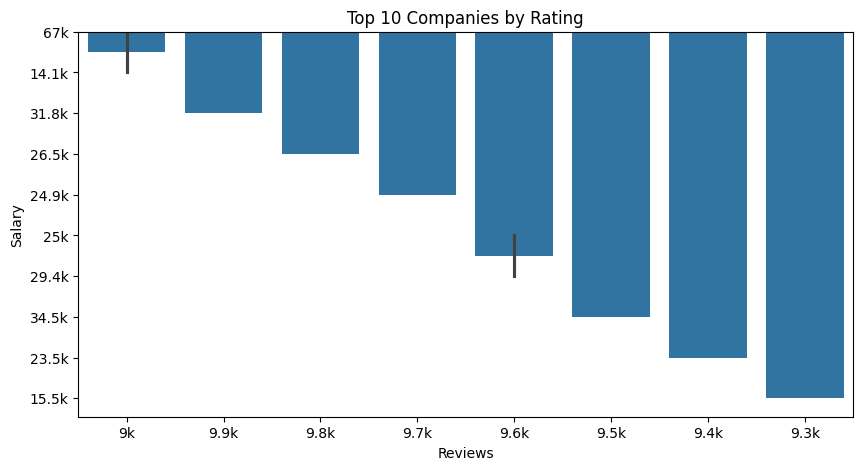

In [13]:
top_companies = df[['Reviews','Salary']].dropna().sort_values(by='Reviews', ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x='Reviews', y='Salary', data=top_companies)
plt.title("Top 10 Companies by Rating")
plt.show()

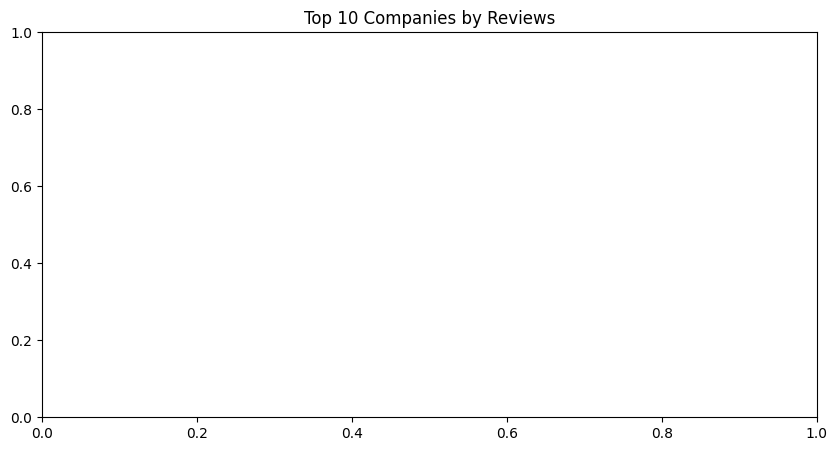

In [16]:
df['Reviews'] = pd.to_numeric(df['Reviews'], errors='coerce')

top_reviews = df[['Company', 'Reviews']].dropna().sort_values(by='Reviews', ascending=False).head(10)

plt.figure(figsize=(10,5))
sns.barplot(x='Reviews', y='Company', data=top_reviews)
plt.title("Top 10 Companies by Reviews")
plt.show()

[]
Empty DataFrame
Columns: [Company, Reviews]
Index: []


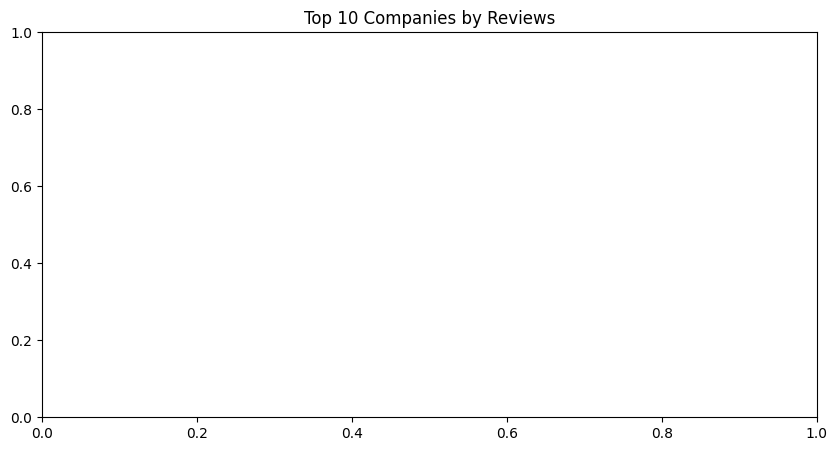

In [26]:


# Show original values
print(df['Reviews'].head(20).tolist())

# Convert Reviews column
df['Reviews'] = df['Reviews'].astype(str)

def convert_reviews(x):
    x = x.strip().lower()

    if 'k' in x:
        return float(x.replace('k', '')) * 1000
    else:
        return float(x)

df['Reviews'] = df['Reviews'].apply(convert_reviews)

# Top 10 companies
top_reviews = df.sort_values(
    by='Reviews',
    ascending=False
)[['Company', 'Reviews']].head(10)

print(top_reviews)

# Plot
plt.figure(figsize=(10,5))
sns.barplot(data=top_reviews, x='Reviews', y='Company')
plt.title("Top 10 Companies by Reviews")
plt.show()

In [28]:
print(df['Jobs'].head(10))
print(df['Jobs'].dtype)

0     4.3k
1    25.2k
2      279
3      779
4     2.2k
5      260
6     2.9k
7      269
8        7
9      644
Name: Jobs, dtype: object
object


0     4300.0
1    25200.0
2      279.0
3      779.0
4     2200.0
Name: Jobs, dtype: float64
float64


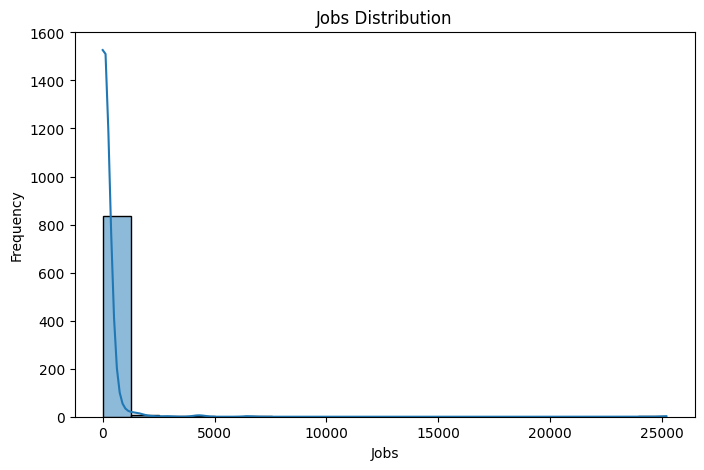

In [31]:
def convert_jobs(x):
    x = str(x).strip().lower()

    if x == '--' or x == '':
        return np.nan

    if x.endswith('k'):
        return float(x[:-1]) * 1000

    if x.endswith('l'):
        return float(x[:-1]) * 100000

    return float(x)

df['Jobs'] = df['Jobs'].apply(convert_jobs)

# Remove missing values
df = df.dropna(subset=['Jobs'])

print(df['Jobs'].head())
print(df['Jobs'].dtype)

plt.figure(figsize=(8,5))
sns.histplot(df['Jobs'], bins=20, kde=True)

plt.title("Jobs Distribution")
plt.xlabel("Jobs")
plt.ylabel("Frequency")
plt.show()

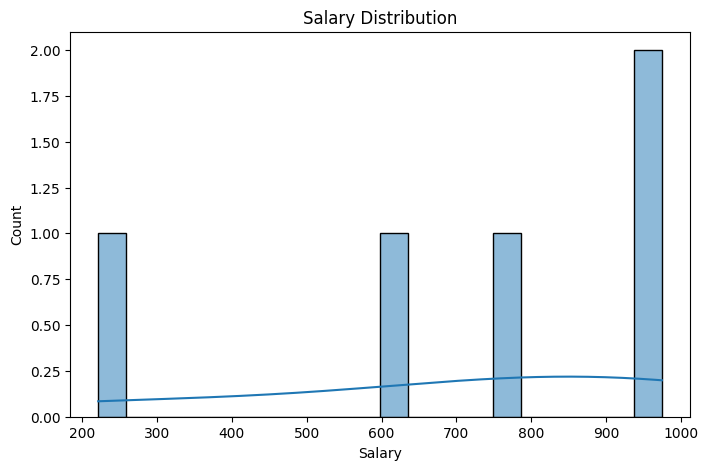

In [33]:
if 'Salary' in df.columns:
    df['Salary'] = pd.to_numeric(df['Salary'], errors='coerce')

    plt.figure(figsize=(8,5))
    sns.histplot(df['Salary'].dropna(), bins=20, kde=True)
    plt.title("Salary Distribution")
    plt.show()

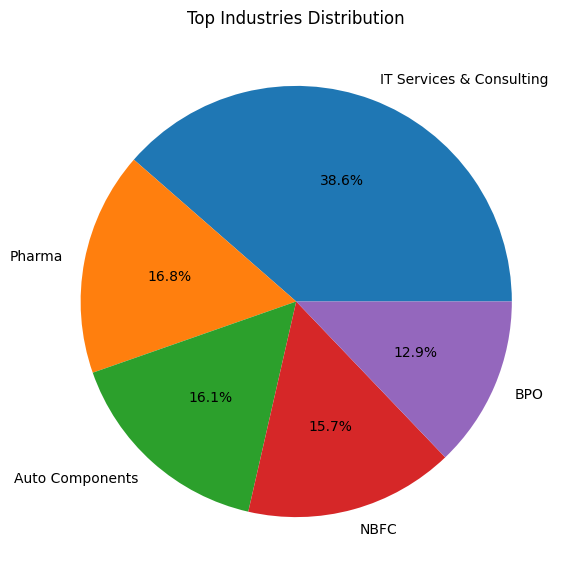

In [34]:
industry_counts = df['Industry'].value_counts().head(5)

plt.figure(figsize=(7,7))
plt.pie(industry_counts, labels=industry_counts.index, autopct='%1.1f%%')
plt.title("Top Industries Distribution")
plt.show()

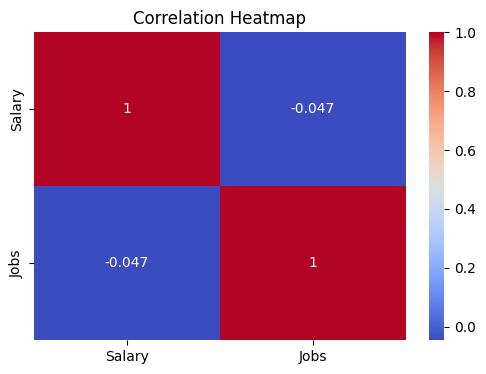

In [35]:
plt.figure(figsize=(6,4))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap='coolwarm')
plt.title("Correlation Heatmap")
plt.show()

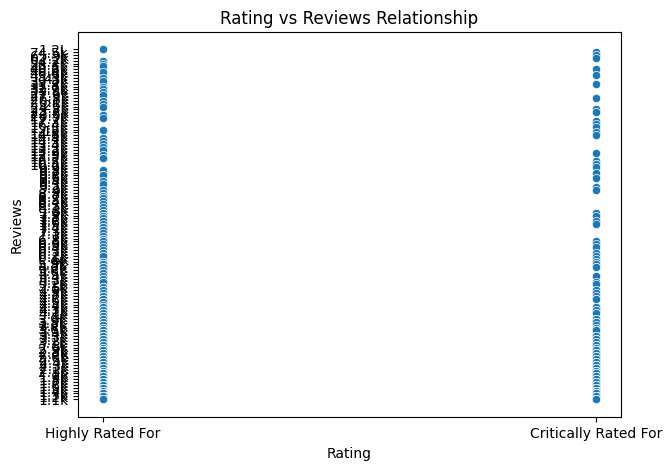

In [36]:
plt.figure(figsize=(7,5))
sns.scatterplot(x='Rating', y='Reviews', data=df)
plt.title("Rating vs Reviews Relationship")
plt.show()

In [42]:

if 'locations' in df.columns:

    primary_cities = df['locations'].dropna().astype(str).str.split().str[0]


    top_locations = primary_cities.value_counts().head(10)

    plt.figure(figsize=(10, 5))
    sns.barplot(x=top_locations.values, y=top_locations.index, palette='viridis')
    plt.title("Top Company Locations (Primary City)")
    plt.xlabel("Number of Companies")
    plt.ylabel("City")
    plt.tight_layout()
    plt.show()

STEP 7: INSIGHTS

Write insights like this 👇

Example Insights:

Most companies have rating between 3
to 4.5

Top-rated companies are mostly IT & Consulting firms

Higher reviews indicate popular companies but not always high rating

IT sector dominates AmbitionBox dataset

Some companies have high reviews but low ratings → customer dissatisfaction




STEP 8: DATA STORY

The dataset shows that IT companies dominate the job market.
Companies with high reviews are not always highly rated, showing mixed employee satisfaction.
Ratings distribution shows most companies are average performers, with few excellent companies.
This analysis helps job seekers choose better companies based on real feedback.

STEP 9: BUILD MINI DASHBOARD

In [44]:
import pandas as pd

df = pd.read_csv('/content/ambitionbox_companies_fixed.csv')

# Remove extra spaces
df.columns = df.columns.str.strip()

# Show all columns
print(df.columns.tolist())

['Company', 'Rating', 'Reviews', 'Salary', 'Interviews', 'Jobs', 'Benefits', 'Industry', 'Location']


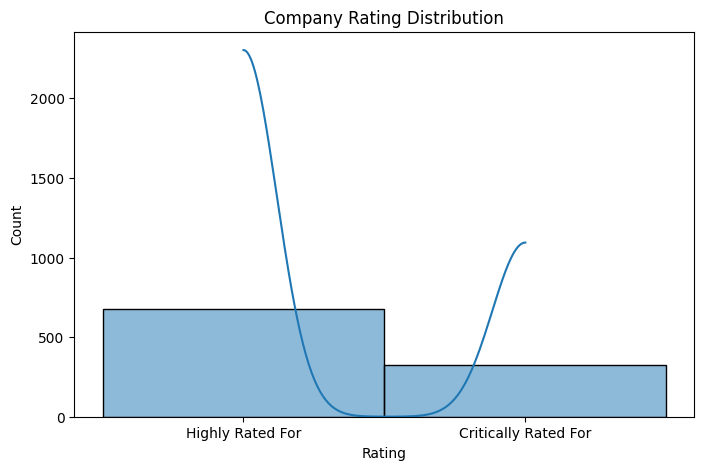

In [46]:
plt.figure(figsize=(8,5))
sns.histplot(df['Rating'], bins=20, kde=True)
plt.title('Company Rating Distribution')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.show()

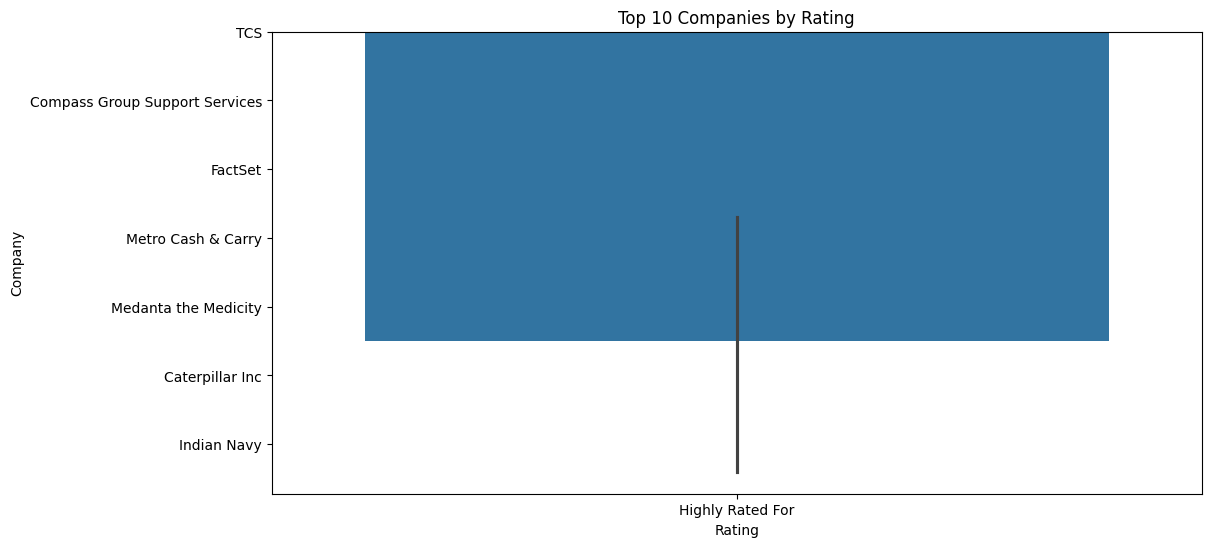

In [45]:
top_rating = (
    df[['Company', 'Rating']]
    .dropna()
    .sort_values(by='Rating', ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=top_rating,
    x='Rating',
    y='Company'
)
plt.title('Top 10 Companies by Rating')
plt.show()

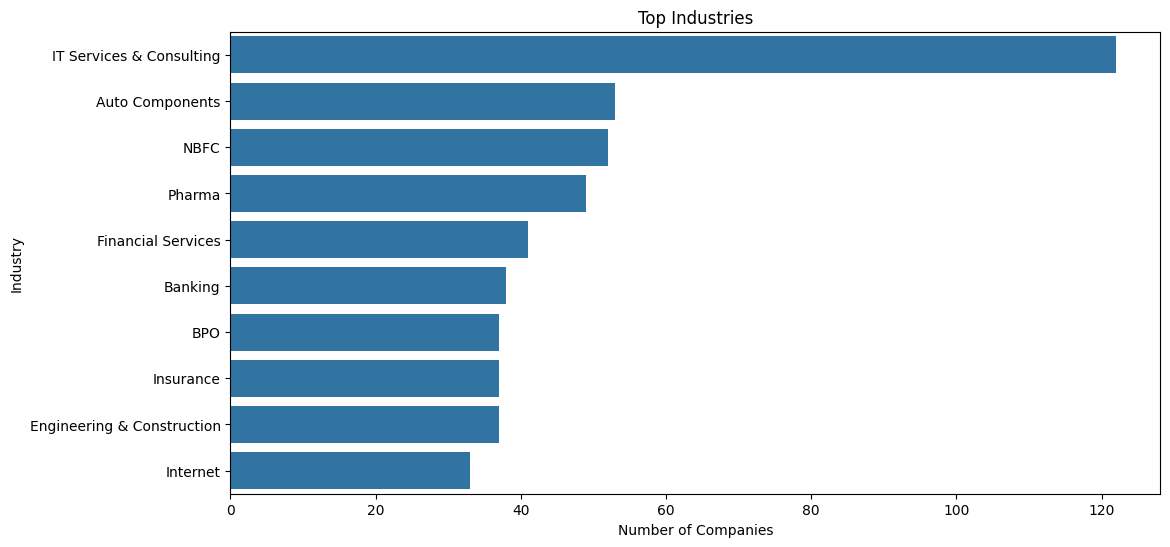

In [47]:
industry_count = df['Industry'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=industry_count.values,
    y=industry_count.index
)
plt.title('Top Industries')
plt.xlabel('Number of Companies')
plt.show()

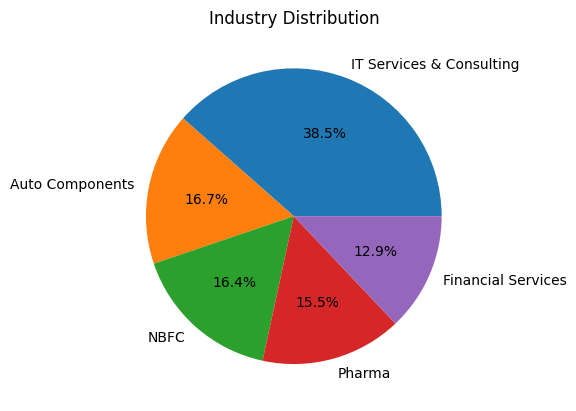

In [48]:
top5 = df['Industry'].value_counts().head(5)

plt.pie(
    top5.values,
    labels=top5.index,
    autopct='%1.1f%%'
)
plt.title('Industry Distribution')
plt.show()

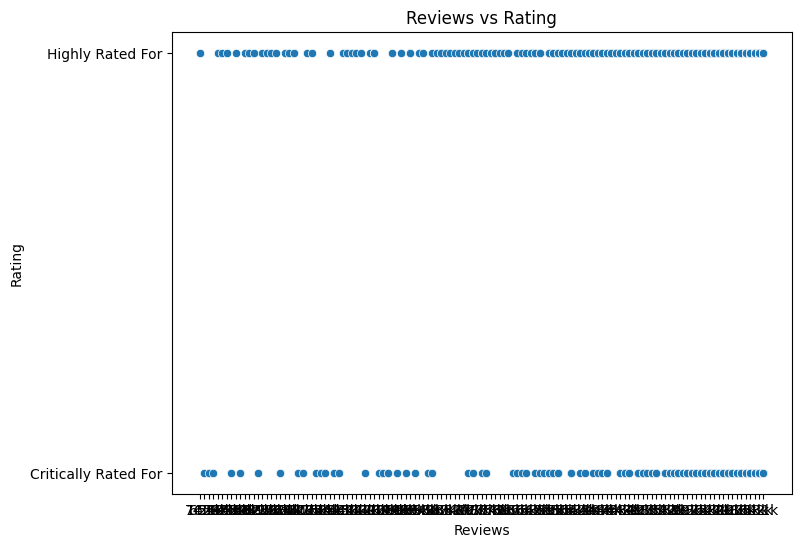

In [49]:
plt.figure(figsize=(8,6))
sns.scatterplot(
    data=df,
    x='Reviews',
    y='Rating'
)
plt.title('Reviews vs Rating')
plt.show()

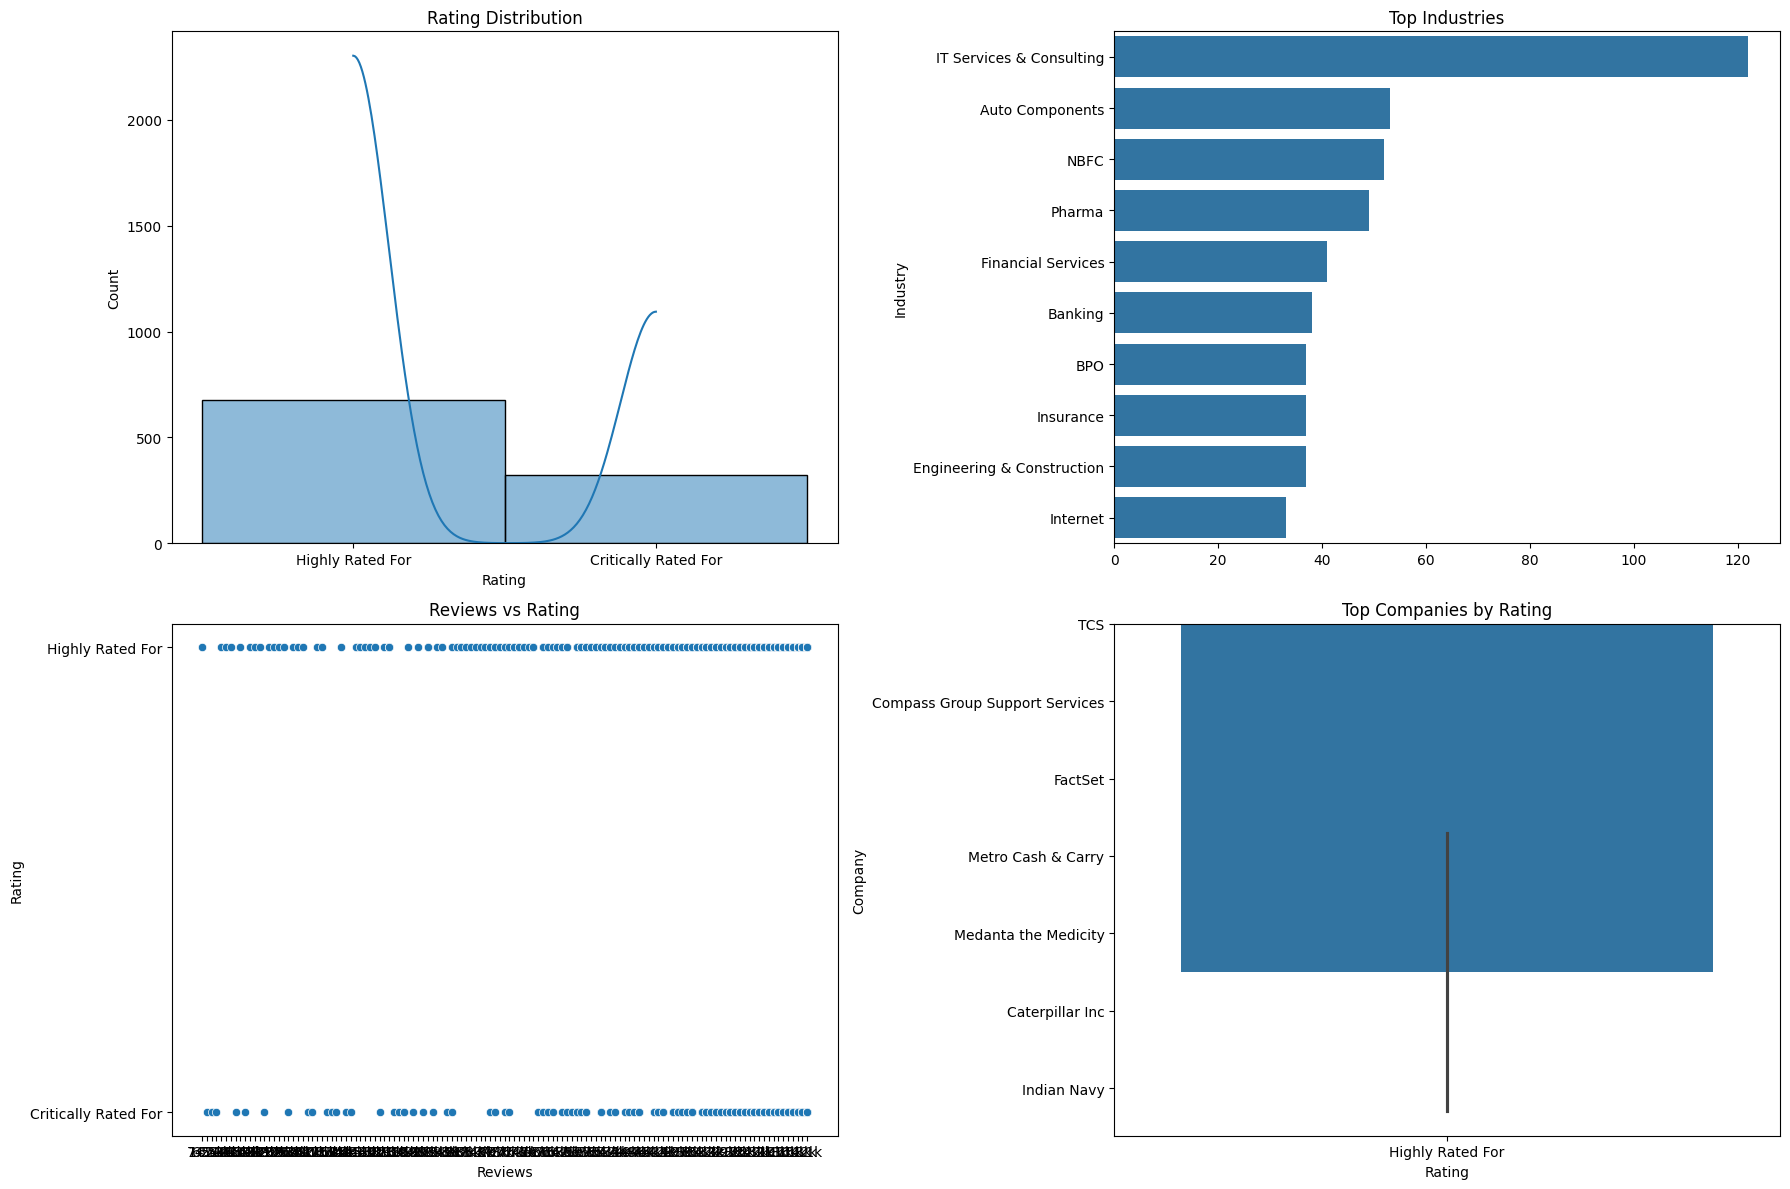

In [50]:
fig, ax = plt.subplots(
    2, 2,
    figsize=(18, 12)
)

sns.histplot(
    df['Rating'],
    kde=True,
    ax=ax[0,0]
)
ax[0,0].set_title('Rating Distribution')

sns.barplot(
    x=industry_count.values,
    y=industry_count.index,
    ax=ax[0,1]
)
ax[0,1].set_title('Top Industries')

sns.scatterplot(
    data=df,
    x='Reviews',
    y='Rating',
    ax=ax[1,0]
)
ax[1,0].set_title('Reviews vs Rating')

sns.barplot(
    data=top_rating,
    x='Rating',
    y='Company',
    ax=ax[1,1]
)
ax[1,1].set_title('Top Companies by Rating')

plt.tight_layout()
plt.show()

**Insights for Report**

Most companies have ratings between 3.5 and 4.5.

IT Services and Consulting companies dominate the dataset.

Higher reviews do not always mean higher ratings.

A few companies have extremely high popularity but average employee satisfaction.

The dataset helps job seekers identify highly rated companies and industries.

Step 8: Top 10 Companies by Reviews

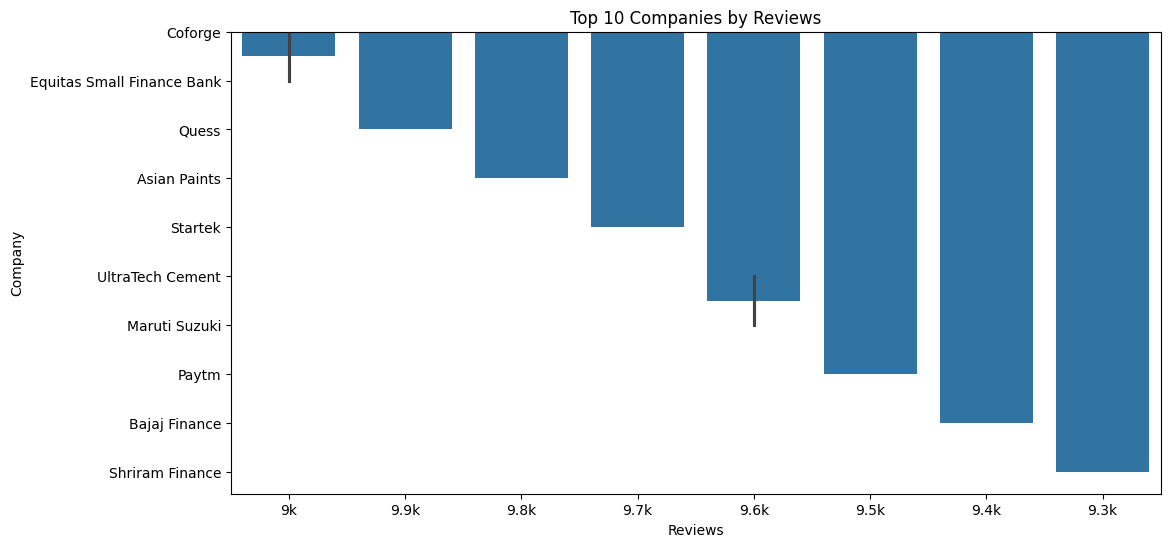

In [51]:
top_reviews = (
    df[['Company', 'Reviews']]
    .dropna()
    .sort_values(by='Reviews', ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=top_reviews,
    x='Reviews',
    y='Company'
)

plt.title('Top 10 Companies by Reviews')
plt.xlabel('Reviews')
plt.ylabel('Company')
plt.show()

Step 9: Top 10 Companies by Salary

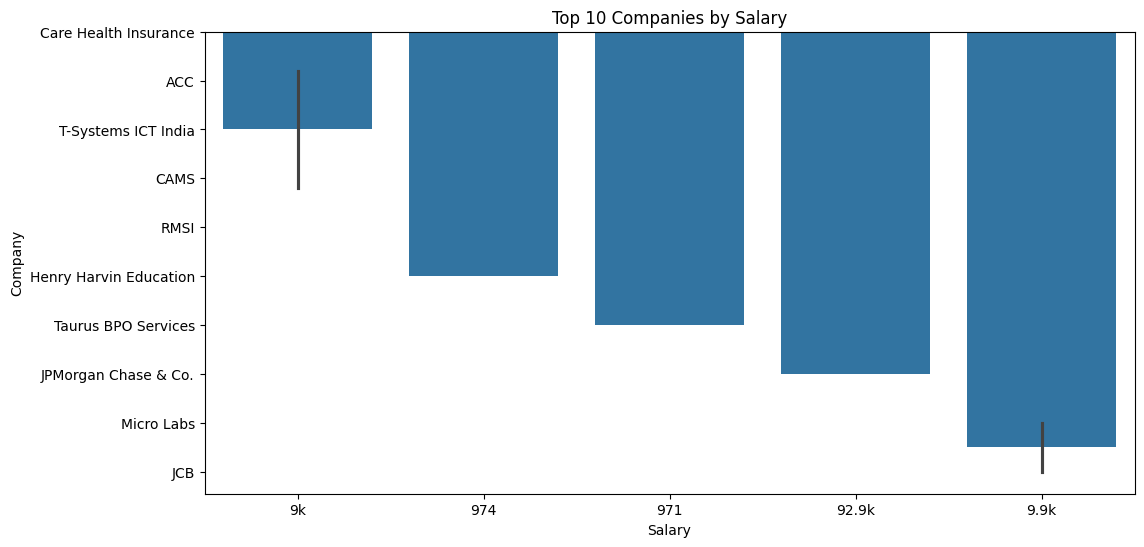

In [52]:
top_salary = (
    df[['Company', 'Salary']]
    .dropna()
    .sort_values(by='Salary', ascending=False)
    .head(10)
)

plt.figure(figsize=(12,6))
sns.barplot(
    data=top_salary,
    x='Salary',
    y='Company'
)

plt.title('Top 10 Companies by Salary')
plt.xlabel('Salary')
plt.ylabel('Company')
plt.show()

Step 10: Top Industries by Number of Companies

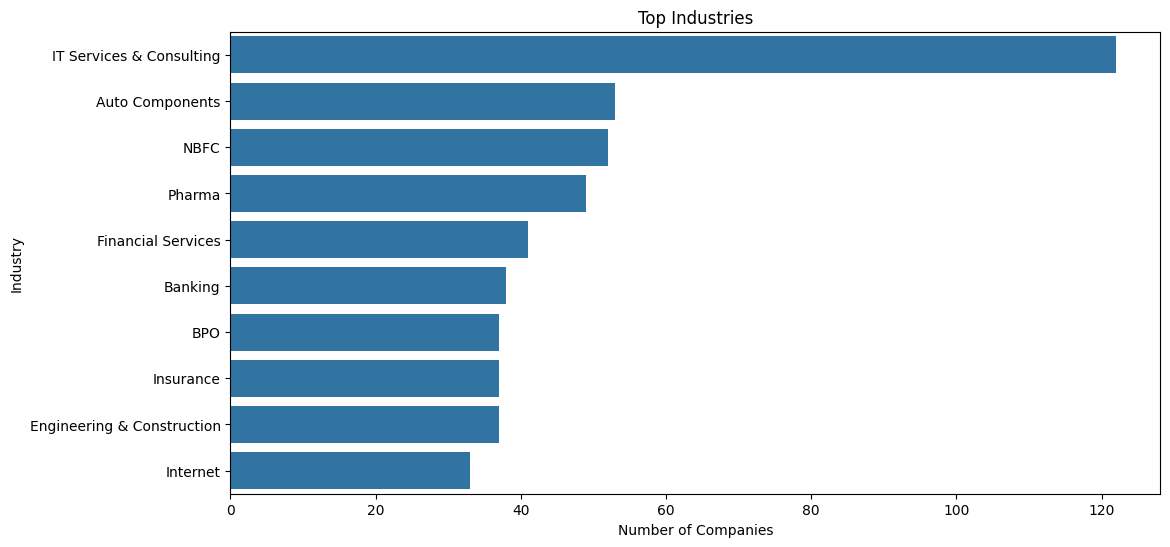

In [53]:
industry_count = df['Industry'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=industry_count.values,
    y=industry_count.index
)

plt.title('Top Industries')
plt.xlabel('Number of Companies')
plt.ylabel('Industry')
plt.show()

Step 11: Top Locations

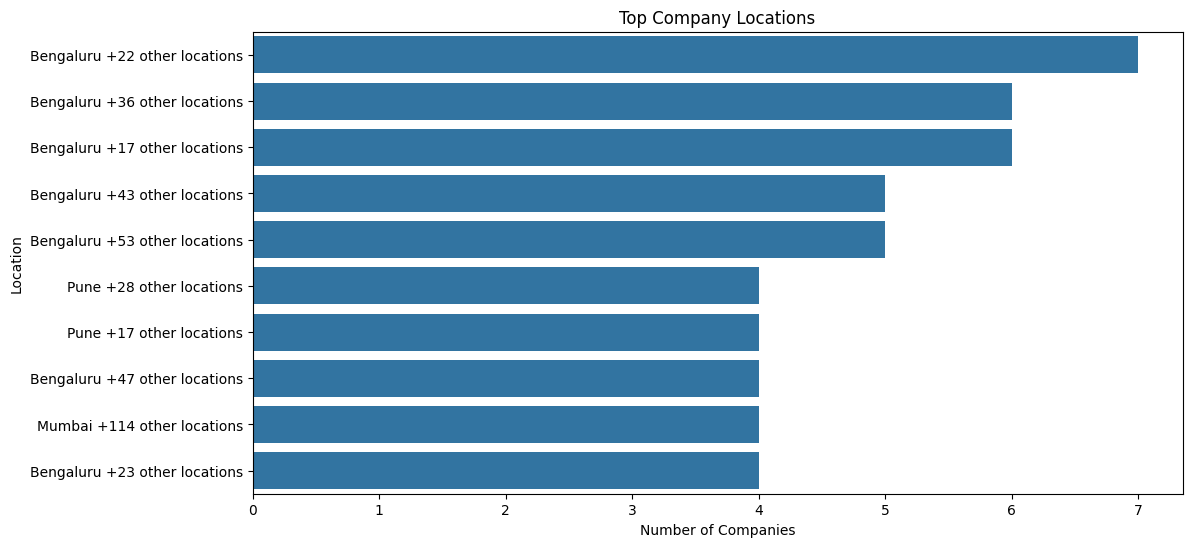

In [54]:
location_count = df['Location'].value_counts().head(10)

plt.figure(figsize=(12,6))
sns.barplot(
    x=location_count.values,
    y=location_count.index
)

plt.title('Top Company Locations')
plt.xlabel('Number of Companies')
plt.ylabel('Location')
plt.show()

Step 12: Correlation Heatmap

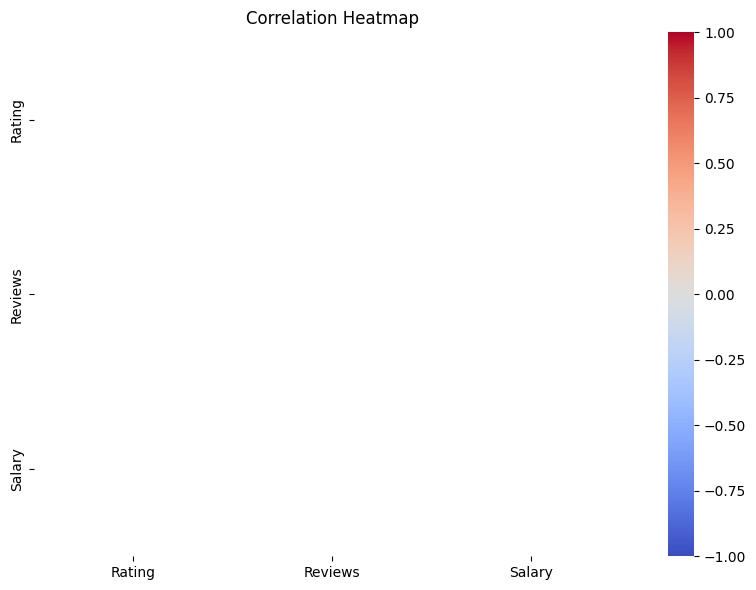

In [56]:


# 1. Create a copy of the columns you want to correlate
numeric_df = df[['Rating', 'Reviews', 'Salary']].copy()

# 2. Function to clean abbreviations like 'k' or 'L' if present
def clean_numeric_suffix(val):
    if pd.isna(val):
        return val
    val = str(val).lower().strip()
    if 'k' in val:
        return float(val.replace('k', '')) * 1000
    if 'l' in val:
        return float(val.replace('l', '')) * 100000
    return val

# 3. Clean and convert each column
for col in numeric_df.columns:
    # Apply suffix cleaning (uncomment the line below if your data uses 'k' or 'L')
    # numeric_df[col] = numeric_df[col].apply(clean_numeric_suffix)

    # Force text like 'Highly Rated For' into NaN
    numeric_df[col] = pd.to_numeric(numeric_df[col], errors='coerce')

# 4. Drop rows that contained text/NaN values so .corr() works perfectly
numeric_df = numeric_df.dropna()

# 5. Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt=".2f",
    vmin=-1,
    vmax=1
)
plt.title('Correlation Heatmap')
plt.tight_layout()
plt.show()

Step 14: Create a Professional Dashboard

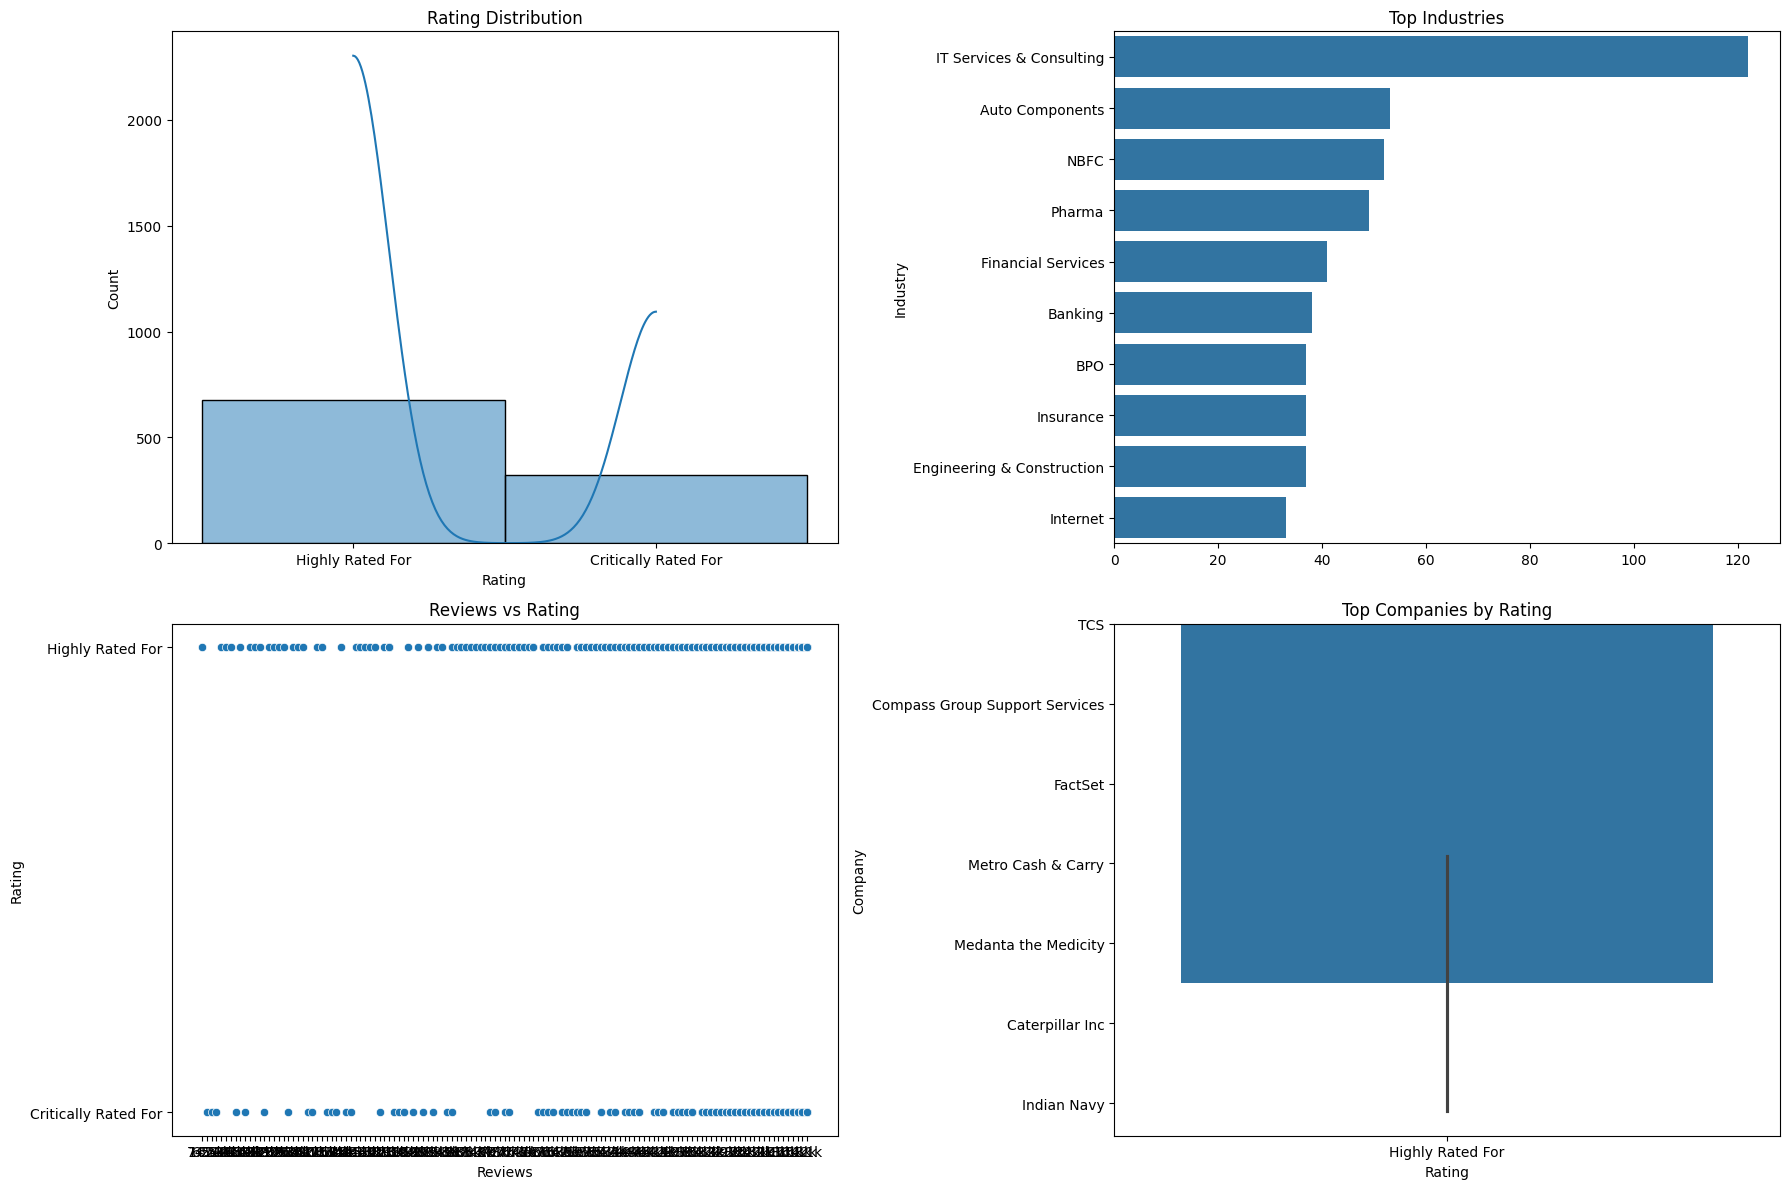

In [57]:
fig, ax = plt.subplots(2, 2, figsize=(18, 12))

# Rating Distribution
sns.histplot(
    df['Rating'],
    kde=True,
    ax=ax[0,0]
)
ax[0,0].set_title('Rating Distribution')

# Top Industries
industry_count = df['Industry'].value_counts().head(10)
sns.barplot(
    x=industry_count.values,
    y=industry_count.index,
    ax=ax[0,1]
)
ax[0,1].set_title('Top Industries')

# Reviews vs Rating
sns.scatterplot(
    data=df,
    x='Reviews',
    y='Rating',
    ax=ax[1,0]
)
ax[1,0].set_title('Reviews vs Rating')

# Top Companies by Rating
top_rating = (
    df[['Company','Rating']]
    .dropna()
    .sort_values(by='Rating', ascending=False)
    .head(10)
)

sns.barplot(
    data=top_rating,
    x='Rating',
    y='Company',
    ax=ax[1,1]
)
ax[1,1].set_title('Top Companies by Rating')

plt.tight_layout()
plt.show()

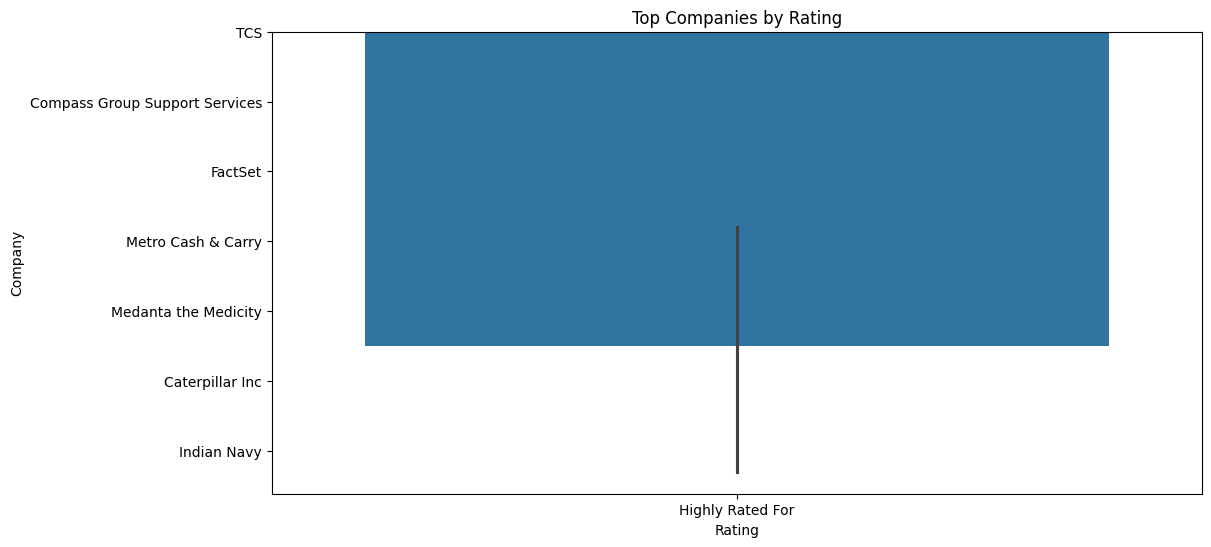

In [58]:
plt.figure(figsize=(12,6))
sns.barplot(
    data=top_rating,
    x='Rating',
    y='Company'
)

plt.title('Top Companies by Rating')
plt.savefig('top_companies_rating.png')
plt.show()

Step 16: Business Insights

Insight 1

Most companies have ratings between 3.5–4.5.


Insight 2


IT Services and Consulting industries dominate the dataset.


Insight 3


Popular companies (high reviews) do not always have high ratings.


Insight 4


Some locations have significantly more companies, indicating business hubs.

Step 17: Data Storytelling

Problem

Job seekers struggle to identify good companies.

Analysis

Analyzed ratings, reviews, salaries, industries, and locations.

Findings

Highly reviewed companies are not always highly rated.

Certain industries consistently receive better ratings.

Recommendation

Job seekers should consider both ratings and reviews before applying.